# Extração de lineamentos topográficos em relevos sombreados do SRTM

Este notebook baixa e reprojeta o modelo de elevação, gera um sombreado por iluminação configurada, extrai segmentos de cada iluminação de forma independente e exporta as geometrias, tabelas, mapas e rosetas. O exemplo executado usa um recorte da **Serra da Canastra, Minas Gerais**, na região da nascente do Rio São Francisco. [Descrição da área pelo ICMBio](https://www.gov.br/icmbio/pt-br/assuntos/unidade-de-conservacao/unidades-de-biomas/cerrado/lista-de-ucs/parna-da-serra-da-canastra/historia-do-parque-nacional-da-serra-da-canastra)

## 1. Preparar o ambiente

Instale o GMT de modo que a biblioteca nativa fique acessível ao PyGMT e selecione um kernel Python no Jupyter. As versões abaixo reproduzem o ambiente de referência. O acesso à rede é necessário caso os dados SRTM ainda não estejam no cache do GMT. [Instalação do PyGMT e do GMT](https://www.pygmt.org/v0.19.0/install.html)

Ambiente de referência **Python 3.14.5 e GMT 6.6.0**. Execute no terminal do ambiente que fornece o kernel.

```bash
python -m pip install numpy==2.5.2 scipy==1.18.1 scikit-image==0.26.0 rasterio==1.5.1 geopandas==1.1.4 pyogrio==0.13.0 pyproj==3.7.2 shapely==2.1.2 matplotlib==3.11.1 pandas==3.0.5 pygmt==0.19.0 pillow==12.3.0 ipykernel==7.4.0
```

In [1]:
from colorsys import hsv_to_rgb
from dataclasses import dataclass
from datetime import date
from hashlib import file_digest
from importlib.metadata import version
from io import BytesIO
from itertools import count
import math
from pathlib import Path
import platform
from tempfile import TemporaryDirectory

import geopandas as gpd
from IPython.display import Image as NotebookImage, display
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from matplotlib.ticker import MaxNLocator, PercentFormatter, ScalarFormatter
import numpy as np
import pandas as pd
from PIL import Image, ImageDraw, ImageFont
from pyproj import Geod, Transformer
import pygmt
import rasterio
from rasterio.io import MemoryFile
from rasterio.warp import calculate_default_transform, reproject, Resampling, transform_bounds
from scipy import ndimage as ndi
from scipy.ndimage import binary_erosion, gaussian_filter
from shapely.geometry import LineString
from skimage.filters import sato
from skimage.morphology import skeletonize
from skimage.transform import probabilistic_hough_line

print("Python", platform.python_version())
print("PyGMT", version("pygmt"), "· GDAL", rasterio.__gdal_version__)

Python 3.14.5
PyGMT 0.19.0 · GDAL 3.12.4


## 2. Parametrizar a área e as iluminações

Defina o nome da área e os dois cantos opostos do recorte. A entrada usa **WGS84 (EPSG:4326)** em graus decimais, na ordem **`(latitude, longitude)`**, como no Google Maps.

No Google Maps, clique com o botão direito no primeiro canto e clique nas coordenadas para copiá-las. Cole os números entre os parênteses de `CANTO_1`. Faça o mesmo para `CANTO_2`. Use ponto como separador decimal. O exemplo vem preenchido com a Serra da Canastra. [Como copiar coordenadas no Google Maps](https://support.google.com/maps/answer/18539?co=GENIE.Platform%3DDesktop&hl=pt-BR)

Adicione ou remova pares em `ILUMINACOES` para definir quantos hillshades serão gerados e analisados. Cada par `(azimute, elevação do Sol)` está em graus. O azimute é medido a partir do norte da grade UTM e a elevação é medida acima do horizonte. Use ao menos um par distinto. A análise de cada iluminação é independente e segue a ordem da lista.

`COMPRIMENTO_MINIMO_M` é dado em metros. Os resultados são gravados em `./linextraction_resultados/<NOME_AREA>/`. Se a pasta já existir, uma nova execução recebe um sufixo como `_02`. Execute com a pasta do notebook como diretório de trabalho do kernel.
**Fonte de elevação:** na célula de parâmetros, escolha `MODELO_ELEVACAO = "copernicus"` (sem chave), `"alos"` (AW3D30), `"anadem"` ou mantenha `"srtm"` (padrão). Para ALOS e ANADEM, defina `OPENTOPOGRAPHY_API_KEY` no ambiente antes de iniciar o notebook. Fontes alternativas são gravadas em `dem/`; o SRTM mantém `srtm/srtm.tif`. O processamento posterior não muda.


In [2]:
# Cole os cantos na ordem (latitude, longitude), como no Google Maps.
NOME_AREA = "Serra da Canastra"
CANTO_1 = (-20.36, -46.72)
CANTO_2 = (-20.11, -46.31)

# srtm (padrão), copernicus (COP30), alos (AW3D30), anadem.
MODELO_ELEVACAO = "srtm"

# Um hillshade por par (azimute, elevação do Sol), em graus.
ILUMINACOES = [
    (45, 45),
    (135, 45),
    (225, 45),
    (315, 45),
]

COMPRIMENTO_MINIMO_M = 600.0
SENSIBILIDADE = "muito-alta"
PASTA_SAIDA = Path("linextraction_resultados") / NOME_AREA

latitude_1, longitude_1 = CANTO_1
latitude_2, longitude_2 = CANTO_2
oeste, leste = sorted((longitude_1, longitude_2))
sul, norte = sorted((latitude_1, latitude_2))
if not (-180 <= oeste < leste <= 180 and -90 <= sul < norte <= 90):
    raise ValueError("Informe dois cantos opostos válidos na ordem (latitude, longitude).")
if MODELO_ELEVACAO not in ("srtm", "copernicus", "alos", "anadem"):
    raise ValueError("Escolha srtm, copernicus, alos ou anadem.")
if not ILUMINACOES:
    raise ValueError("Informe pelo menos uma iluminação.")
if not all(0 <= az < 360 and 0 <= alt <= 90 for az, alt in ILUMINACOES):
    raise ValueError("Use azimutes de 0° a menos de 360° e elevações de 0° a 90°.")
if len(set(ILUMINACOES)) != len(ILUMINACOES):
    raise ValueError("Informe pares de azimute e elevação distintos.")
if not math.isfinite(COMPRIMENTO_MINIMO_M) or COMPRIMENTO_MINIMO_M <= 0:
    raise ValueError("Informe um comprimento mínimo positivo em metros.")

if (
    not NOME_AREA.strip() or NOME_AREA in (".", "..") or NOME_AREA.endswith((".", " "))
    or any(caractere in NOME_AREA for caractere in '/\\:*?"<>|')
):
    raise ValueError("Use um nome de área válido para uma única pasta.")

REGIAO = oeste, leste, sul, norte
print(f"{NOME_AREA} · Limites em WGS84 (O, L, S, N) {REGIAO}")
print(f"Iluminações configuradas · {len(ILUMINACOES)}")

Serra da Canastra · Limites em WGS84 (O, L, S, N) (-46.72, -46.31, -20.36, -20.11)
Iluminações configuradas · 4


## 3. Baixar o SRTM e reprojetar para UTM

O recorte usa o SRTM de 1 segundo de arco distribuído pelo GMT. O GeoTIFF original é exportado em `srtm/`, em WGS84. Uma cópia intermediária é reprojetada por interpolação bilinear para a zona UTM do centro da área, de modo a trabalhar com distâncias métricas. [Dados SRTM no GMT](https://www.generic-mapping-tools.org/remote-datasets/srtm-relief.html) · [NASA SRTMGL1 V003](https://doi.org/10.5067/MEaSUREs/SRTM/SRTMGL1.003)

In [3]:
def download_srtm(region, destination):
    import pygmt

    with TemporaryDirectory() as temp:
        grid = Path(temp) / "srtm.nc"
        pygmt.grdcut(grid="@srtm_relief_01s", region=region, outgrid=grid)
        with rasterio.open(grid) as src:
            elevation = src.read(1, masked=True).astype(np.float32)
            profile = dict(
                driver="GTiff", height=src.height, width=src.width, count=1,
                dtype="float32", crs="EPSG:4326", transform=src.transform,
                nodata=np.nan, compress="lzw",
            )
        if min(elevation.shape) < 2 or elevation.count() == 0:
            raise ValueError("O recorte SRTM precisa ter pelo menos duas linhas e duas colunas de elevação.")
        with rasterio.open(destination, "w", **profile) as dst:
            dst.write(elevation.filled(np.nan), 1)


SOURCE_CRS = "EPSG:4326"  # SRTM datum (WGS84 geographic)


def utm_epsg_for(lon: float, lat: float) -> str:
    zone = min(60, int(math.floor((lon + 180) / 6) + 1))
    prefix = "EPSG:327" if lat < 0 else "EPSG:326"
    return f"{prefix}{zone:02d}"


def reproject_to_utm(src_path: str, dst_path: str, resolution: float | None = None) -> str:
    """Reproject a DEM to UTM, assuming WGS84 for a grid with no embedded CRS."""
    with rasterio.open(src_path) as src:
        data = np.ma.masked_invalid(src.read(1, masked=True))
        nodata = src.nodata
        if nodata is None:
            data = data.astype(np.float32)
            nodata = np.nan
        data = data.filled(nodata)
        # GDAL needs the CRS embedded for sources such as ASCII grids.
        mem_profile = dict(
            driver="GTiff", dtype=data.dtype, count=1, crs=src.crs or SOURCE_CRS,
            nodata=nodata, transform=src.transform, height=src.height, width=src.width,
        )

    with MemoryFile() as memfile:
        with memfile.open(**mem_profile) as mem:
            mem.write(data, 1)

        with memfile.open() as mem:
            west, south, east, north = transform_bounds(mem.crs, SOURCE_CRS, *mem.bounds)
            lon_c = (west + east) / 2
            lat_c = (south + north) / 2
            dst_crs = utm_epsg_for(lon_c, lat_c)

            transform, width, height = calculate_default_transform(
                mem.crs, dst_crs, mem.width, mem.height, *mem.bounds,
                resolution=resolution,
            )
            profile = mem.profile.copy()
            profile.pop("blockxsize", None)
            profile.pop("blockysize", None)
            profile.update(
                crs=dst_crs,
                transform=transform,
                width=width,
                height=height,
                driver="GTiff",
                compress="lzw",
            )

            with rasterio.open(dst_path, "w", **profile) as dst:
                reproject(
                    source=rasterio.band(mem, 1),
                    destination=rasterio.band(dst, 1),
                    resampling=Resampling.bilinear,
                )
    return dst_crs

In [4]:
PASTA_SAIDA.parent.mkdir(parents=True, exist_ok=True)
trabalho = TemporaryDirectory(prefix=".calculo-", dir=PASTA_SAIDA.parent)
temporario = Path(trabalho.name)
resultado_temporario = temporario / "resultado"

for pasta in (("srtm" if MODELO_ELEVACAO == "srtm" else "dem"), "hillshades", "shapefile", "sobreposicoes", "rosetas/segmentos", "rosetas/frequencia"):
    (resultado_temporario / pasta).mkdir(parents=True, exist_ok=True)

mde_original = resultado_temporario / ("srtm" if MODELO_ELEVACAO == "srtm" else "dem") / ("srtm.tif" if MODELO_ELEVACAO == "srtm" else f"{MODELO_ELEVACAO}.tif")
mde_utm = temporario / "mde_utm.tif"
if MODELO_ELEVACAO == "srtm":
    download_srtm(REGIAO, mde_original)
else:
    from linextraction_dem import download_alternative_dem
    download_alternative_dem(MODELO_ELEVACAO, REGIAO, mde_original)
crs = reproject_to_utm(mde_original, mde_utm)
with rasterio.open(mde_utm) as raster:
    print(f"{crs} · {raster.width} × {raster.height} células · espaçamento de {raster.res[0]:.2f} m")
with mde_original.open("rb") as arquivo:
    print("SHA-256 do GeoTIFF de elevação", file_digest(arquivo, "sha256").hexdigest())
print("Data da execução local", date.today().isoformat())print("Fonte de elevação", MODELO_ELEVACAO)


EPSG:32723 · 1462 × 952 células · espaçamento de 29.50 m
SHA-256 do GeoTIFF de elevação 41dd09e143705a79addd8ee0b7611b311c736f00c480ae7f5565b5b2a89a1e6e
Data da execução local 2026-11-19


## 4. Gerar os sombreados e a declividade

O sombreamento segue a formulação lambertiana do mapa de reflectância com gradientes calculados sobre o SRTM projetado. A declividade, expressa como razão entre desnível e distância horizontal, é calculada após uma suavização gaussiana e reforça as propostas da busca principal. Cada GeoTIFF sombreado fica na mesma grade UTM. [Horn, 1981](https://doi.org/10.1109/PROC.1981.11918)

In [5]:
def hillshade(elevation: np.ndarray, cellsize_x: float, cellsize_y: float,
               azimuth_deg: float, altitude_deg: float = 45.0) -> np.ndarray:
    """Lambertian hillshade from the reflectance-map formulation of
    Horn (1981, Proceedings of the IEEE 69(1):14-47): shading is a function
    of surface gradient (via slope/aspect) and illumination geometry alone.
    azimuth_deg is compass degrees (0=N, 90=E); altitude_deg is sun elevation
    above the horizon.
    """
    az = np.radians(360.0 - azimuth_deg + 90.0)
    alt = np.radians(altitude_deg)

    dzdx = np.gradient(elevation, axis=1) / cellsize_x
    dzdy = np.gradient(elevation, axis=0) / cellsize_y

    slope = np.arctan(np.hypot(dzdx, dzdy))
    aspect = np.arctan2(dzdy, -dzdx)

    shaded = (np.sin(alt) * np.cos(slope) +
              np.cos(alt) * np.sin(slope) * np.cos(az - aspect))
    return np.clip(shaded * 255.0, 0, 255).astype(np.uint8)


def terrain_slope(dem_path: Path) -> np.ndarray:
    """Compute rise/run from the metric DEM, suppressing single-cell noise."""
    with rasterio.open(dem_path) as src:
        elevation = src.read(1, masked=True).astype(np.float32)
        if min(elevation.shape) < 2 or elevation.count() == 0:
            raise ValueError("O modelo de elevação precisa conter um recorte válido de pelo menos 2 por 2 pixels.")
        smooth = gaussian_filter(elevation.filled(float(elevation.mean())), 2)
        dy, dx = np.gradient(smooth, src.res[1], src.res[0])
    return np.hypot(dx, dy)


def format_angle(angle: float) -> str:
    return str(angle or 0.0).removesuffix(".0")


def make_hillshades(
    dem_path: Path, out_dir: Path, lights: list[tuple[float, float]],
) -> list[Path]:
    out_paths = []
    with rasterio.open(dem_path) as src:
        elevation = src.read(1, masked=True).astype(np.float64)
        valid = ~np.ma.getmaskarray(elevation)
        if min(elevation.shape) < 2 or not valid.any():
            raise ValueError("O modelo de elevação não contém pixels válidos.")
        elevation = elevation.filled(float(elevation.mean()))
        # The hillshade gradient needs valid neighbors on both axes.
        valid = binary_erosion(valid, border_value=1)
        cellsize_x = src.transform.a
        cellsize_y = -src.transform.e
        profile = src.profile.copy()
        profile.update(dtype="uint8", count=1, nodata=None, compress="lzw")

        for azimuth, altitude in lights:
            shade = hillshade(elevation, cellsize_x, cellsize_y, azimuth, altitude)
            azimuth_label = format_angle(azimuth).replace(".", "_")
            altitude_label = format_angle(altitude).replace(".", "_")
            out_path = out_dir / f"hillshade_az{azimuth_label}_alt{altitude_label}.tif"
            with rasterio.open(out_path, "w", **profile) as dst:
                dst.write(shade, 1)
                dst.write_mask(valid)
                dst.update_tags(azimute=format_angle(azimuth), altura=format_angle(altitude))
            out_paths.append(out_path)
    return out_paths

In [6]:
declividade = terrain_slope(mde_utm)
sombreados = make_hillshades(mde_utm, resultado_temporario / "hillshades", ILUMINACOES)
print("\n".join(path.name for path in sombreados))

hillshade_az45_alt45.tif
hillshade_az135_alt45.tif
hillshade_az225_alt45.tif
hillshade_az315_alt45.tif


## 5. Detectar os lineamentos

A busca principal usa uma grade com resolução alvo de 90 m. O filtro multiescala de Sato realça faixas escuras alongadas. As respostas são afinadas em linhas de um pixel e a transformada de Hough probabilística propõe retas. O ajuste usa amostras transversais para aproximar a reta do eixo escuro, verificar a direção local e recortar trechos com apoio insuficiente. A semente da transformada é fixa. [Sato et al., 1998](https://doi.org/10.1016/S1361-8415(98)80009-1) · [Galambos, Matas e Kittler, 1999](https://dspace.cvut.cz/server/api/core/bitstreams/acff0e10-6490-4022-8fcc-2bb408e4df6c/content)

No modo padrão, são selecionados até **96 segmentos principais e 24 complementares por iluminação**. A busca complementar usa uma grade com resolução alvo de 60 m, prioriza eixos estreitos com contraste local e continuidade e exclui segmentos muito próximos e paralelos aos já selecionados. A geometria da busca principal é mantida na etapa complementar. A resolução da grade de análise é obtida por subamostragem do raster UTM.

Os segmentos são candidatos a lineamentos topográficos. A seleção depende da iluminação escolhida e dos limiares do detector. A interpretação estrutural exige evidências geológicas independentes.

In [7]:
type Segment = tuple[tuple[float, float], tuple[float, float]]


@dataclass(frozen=True)
class Sensitivity:
    seed_quantile: float
    min_prominence: float
    min_coverage: float
    hough_votes: int
    max_lines: int


DEFAULT_SENSITIVITY = "muito-alta"
DEFAULT_SUPPLEMENTAL_LIMIT = 24
SENSITIVITIES = {
    "conservadora": Sensitivity(0.91, 0.015, 0.68, 9, 32),
    "moderada": Sensitivity(0.88, 0.013, 0.64, 8, 48),
    "alta": Sensitivity(0.84, 0.011, 0.59, 7, 72),
    "muito-alta": Sensitivity(0.79, 0.009, 0.54, 6, 96),
}


def _transverse_peaks(centers, normal, offsets, score, axis, valid):
    """Sample the strongest aligned image axis in a narrow transverse profile."""
    cross_section = centers + offsets[:, None, None] * normal
    coordinates = cross_section[..., ::-1].transpose(2, 0, 1)
    x, y = np.rint(cross_section).astype(int).transpose(2, 0, 1)
    x = x.clip(0, score.shape[1] - 1)
    y = y.clip(0, score.shape[0] - 1)
    angle = math.atan2(normal[1], normal[0])
    aligned = np.abs(np.cos(axis[y, x] - angle)) >= 0.77
    values = ndi.map_coordinates(score, coordinates, order=1)
    values *= aligned & valid[y, x]
    peak = (values * (1 - 0.10 * np.abs(offsets[:, None]))).argmax(axis=0)
    return values[peak, np.arange(len(centers))], offsets[peak]


def _fit_offset(stations, offsets):
    x = stations - stations.mean()
    slope = np.dot(x, offsets - offsets.mean()) / np.dot(x, x)
    intercept = offsets.mean() - slope * stations.mean()
    return slope, intercept


def _refit(start, end, score, axis, valid, cutoff, min_pixels, min_coverage, *, fine):
    """Adjust a Hough proposal to the local axis and trim unsupported ends."""
    delta = np.subtract(end, start)
    length = np.linalg.norm(delta)
    if length < min_pixels:
        return []
    tangent = delta / length
    normal = np.array([-tangent[1], tangent[0]])
    stations = np.linspace(0, length, math.ceil(length) + 1)
    centers = start + stations[:, None] * tangent
    strength, offsets = _transverse_peaks(centers, normal, np.arange(-2, 2.1, 0.5), score, axis, valid)
    hit = strength >= 0.55 * cutoff
    if hit.sum() < max(5, 0.48 * len(stations)):
        return []

    slope, intercept = _fit_offset(stations[hit], offsets[hit])
    hit &= np.abs(offsets - (slope * stations + intercept)) <= 1.15
    if hit.sum() < max(5, 0.42 * len(stations)):
        return []
    slope, intercept = _fit_offset(stations[hit], offsets[hit])
    if abs(slope) > math.tan(math.radians(14)):
        return []

    # Recheck the fitted line, with a few extra samples at each end.
    origin = start + intercept * normal
    direction = tangent + slope * normal
    extension = 7 if fine else 5
    stations = np.arange(-extension, math.ceil(length) + extension + 1, dtype=float)
    centers = origin + stations[:, None] * direction
    normal = np.array([-direction[1], direction[0]]) / np.linalg.norm(direction)
    strength, offsets = _transverse_peaks(centers, normal, np.arange(-1, 1.1, 0.5), score, axis, valid)

    support = np.flatnonzero(strength >= 0.52 * cutoff)
    runs = np.split(support, np.flatnonzero(np.diff(support) > 4) + 1)
    results = []
    for run in runs:
        if len(run) < 2:
            continue
        first, last = run[[0, -1]]
        section = centers[first:last + 1]
        covered = len(run) / len(section)
        extent = np.linalg.norm(section[-1] - section[0])
        if extent < min_pixels or covered < min_coverage:
            continue

        # A parallel, offset shadow is weaker evidence than an axis under the line.
        centered = np.mean(np.abs(offsets[run]) <= 0.5)
        if centered < 0.55:
            continue
        sx, sy = np.rint(section).astype(int).T
        if (sx.min() < 2 or sx.max() >= valid.shape[1] - 2 or
                sy.min() < 2 or sy.max() >= valid.shape[0] - 2 or not valid[sy, sx].all()):
            continue
        signal = min(strength[run].mean() / (3 * cutoff), 1)
        span_weight = extent**0.72 if fine else extent
        contrast_weight = (0.42 + 0.58 * signal) if fine else (0.72 + 0.28 * signal)
        quality = span_weight * covered**1.5 * (0.65 + 0.35 * centered) * contrast_weight
        results.append((quality, tuple(section[0]), tuple(section[-1]), sx, sy))
    return results


def _axis_normal(image, sigma):
    dxx = ndi.gaussian_filter(image, sigma, order=(0, 2))
    dyy = ndi.gaussian_filter(image, sigma, order=(2, 0))
    dxy = ndi.gaussian_filter(image, sigma, order=(1, 1))
    return 0.5 * np.arctan2(2 * dxy, dxx - dyy)

In [8]:
def _detect_at_scale(hillshade, pixel_size, min_length_m, max_lines, slope, settings, *, fine):
    stride = max(1, round((60 if fine else 90) / pixel_size))
    image = np.ma.asarray(hillshade)[::stride, ::stride].astype(np.float32) / 255
    interior = ndi.binary_erosion(~np.ma.getmaskarray(image), iterations=3 if fine else 6)
    min_pixels = min_length_m / (pixel_size * stride)
    if not interior.any() or min_pixels > math.hypot(*image.shape):
        return []

    luminance = image.filled(float(np.ma.median(image)))
    smooth = ndi.gaussian_filter(luminance, 0.85)
    prominence = np.maximum(ndi.gaussian_filter(luminance, 6) - smooth, 0)
    if fine and np.quantile(prominence[interior], 0.99) < settings.min_prominence:
        prominence = np.maximum(ndi.gaussian_filter(luminance, 9) - smooth, 0)
    if not (prominence[interior] > settings.min_prominence).any():
        return []

    linear = sato(smooth, sigmas=(2, 3.4), black_ridges=True)
    score = np.sqrt(linear * prominence)
    seed_score = score * (0.65 + 0.35 * np.clip((np.median(smooth[interior]) - smooth) / 0.3, 0, 1))
    if slope is not None:
        seed_score *= 1 + 0.20 * np.clip(slope[::stride, ::stride] / 0.35, 0, 1)

    dark_axes = interior & (prominence > settings.min_prominence) & (score > 0)
    if not dark_axes.any():
        return []
    cutoff = max(np.quantile(seed_score[interior], settings.seed_quantile),
                 np.quantile(seed_score[dark_axes], 0.10))
    min_hough_length = max(3, math.ceil(min_pixels / math.sqrt(2)))
    seeds = skeletonize(dark_axes & (seed_score > 0.88 * cutoff))
    strong_seeds = skeletonize(dark_axes & (seed_score > 1.22 * cutoff))
    proposals = set()
    for points in (seeds, strong_seeds):
        proposals.update(probabilistic_hough_line(
            points, threshold=settings.hough_votes, line_length=min_hough_length, line_gap=12, rng=0,
        ))
    proposals.update(probabilistic_hough_line(
        ndi.binary_dilation(seeds), threshold=22, line_length=max(15, min_hough_length),
        line_gap=7, rng=0,
    ))

    axis = _axis_normal(smooth, sigma=2)
    # Use an image-only threshold for fitting; the slope only affects proposals.
    fit_cutoff = max(np.quantile(score[interior], settings.seed_quantile),
                     np.quantile(score[dark_axes], 0.10))
    coverage = max(0.62, settings.min_coverage)
    scored = []
    for start, end in proposals:
        scored.extend(_refit(start, end, score, axis, interior, fit_cutoff, min_pixels, coverage, fine=fine))

    claimed = np.zeros(image.shape, dtype=np.uint16)
    selected = []
    for _, start, end, sx, sy in sorted(scored, key=lambda row: row[:3], reverse=True):
        dx, dy = np.subtract(end, start)
        angle_bin = round(math.atan2(dy, dx) * 12 / math.pi) % 12
        parallel = sum(1 << ((angle_bin + offset) % 12) for offset in (-1, 0, 1))
        if np.mean((claimed[sy, sx] & parallel) != 0) > 0.53:
            continue
        selected.append((tuple(np.multiply(start, stride)), tuple(np.multiply(end, stride))))
        if len(selected) == max_lines:
            break
        for y_offset in (-1, 0, 1):
            for x_offset in (-1, 0, 1):
                claimed[sy + y_offset, sx + x_offset] |= 1 << angle_bin
    return selected


def _add_distinct_segments(baseline, candidates, pixel_size, limit):
    """Keep the accepted geometry and append nearby discoveries only when distinct."""
    selected = list(baseline)
    tolerance = 120 / pixel_size
    min_alignment = math.cos(math.radians(20))
    for segment in candidates:
        if selected:
            starts, ends = np.asarray(selected).transpose(1, 0, 2)
            vectors = ends - starts
            lengths = np.linalg.norm(vectors, axis=1)
            direction = np.subtract(segment[1], segment[0])
            direction /= np.linalg.norm(direction)
            parallel = np.abs(vectors @ direction) >= min_alignment * lengths
            near_starts = starts[parallel]
            near_vectors = vectors[parallel]
            spacing = max(2, math.ceil(math.dist(*segment) * pixel_size / 60) + 1)
            samples = np.linspace(*segment, spacing)
            offsets = samples[:, None, :] - near_starts
            along = np.einsum("sni,ni->sn", offsets, near_vectors) / lengths[parallel]**2
            distances = np.linalg.norm(offsets - along.clip(0, 1)[..., None] * near_vectors, axis=2)
            if np.mean(np.any(distances <= tolerance, axis=1)) >= 0.45:
                continue
        selected.append(segment)
        if len(selected) == len(baseline) + limit:
            break
    return selected


def _detect_dark_axes(hillshade, pixel_size, min_length_m, limit):
    """Look for narrow, locally dark axes with continuous image support."""
    stride = max(1, round(60 / pixel_size))
    spacing = pixel_size * stride
    image = np.ma.asarray(hillshade)[::stride, ::stride].astype(np.float32) / 255
    interior = ndi.binary_erosion(~np.ma.getmaskarray(image), iterations=4)
    min_pixels = min_length_m / spacing
    if not interior.any() or min_pixels > math.hypot(*image.shape):
        return []

    luminance = image.filled(float(np.ma.median(image)))
    smooth = ndi.gaussian_filter(luminance, 0.55)
    prominence = np.maximum(ndi.gaussian_filter(luminance, 5) - smooth, 0)
    darkness = np.clip((np.median(smooth[interior]) - smooth) / 0.30, 0, 1)
    eligible = interior & (prominence > 0.028) & (darkness > 0.10)
    if not eligible.any():
        return []

    ridge = sato(smooth, sigmas=(1, 1.6, 2.5), black_ridges=True)
    score = np.sqrt(ridge * prominence) * (0.36 + 0.64 * darkness)
    eligible &= score > 0
    if not eligible.any():
        return []
    cutoff = max(np.quantile(score[interior], 0.94), np.quantile(score[eligible], 0.12))
    proposals = set()
    for threshold in (0.82, 1.22):
        seeds = skeletonize(eligible & (score > threshold * cutoff))
        proposals.update(probabilistic_hough_line(
            seeds, threshold=max(7, round(min_pixels * 0.7)),
            line_gap=max(3, round(185 / spacing)),
            line_length=max(3, math.ceil(min_pixels / math.sqrt(2))), rng=0,
        ))

    supporting_score = np.where(eligible, score, 0)
    axis = _axis_normal(smooth, sigma=1.55)
    scored = []
    for start, end in proposals:
        scored.extend(_refit(
            start, end, supporting_score, axis, interior, cutoff, min_pixels, 0.72, fine=True,
        ))
    candidates = [
        (tuple(np.multiply(start, stride)), tuple(np.multiply(end, stride)))
        for _, start, end, _, _ in sorted(scored, key=lambda row: row[:3], reverse=True)
    ]
    return _add_distinct_segments([], candidates, pixel_size, limit)


def detect_segments(
    hillshade: np.ma.MaskedArray, pixel_size: float, min_length_m: float, max_lines: int,
    *, slope: np.ndarray | None = None, sensitivity: str = DEFAULT_SENSITIVITY, supplemental_limit: int = 0,
) -> list[Segment]:
    """Return the main detections, followed by optional distinct finer detections."""
    settings = SENSITIVITIES[sensitivity]
    baseline = _detect_at_scale(hillshade, pixel_size, min_length_m, max_lines, slope, settings, fine=False)
    if supplemental_limit <= 0:
        return baseline
    pool = max(max_lines, 5 * supplemental_limit)
    dark = _detect_dark_axes(hillshade, pixel_size, min_length_m, pool)
    selected = _add_distinct_segments(baseline, dark, pixel_size, supplemental_limit)
    remaining = len(baseline) + supplemental_limit - len(selected)
    if remaining == 0:
        return selected
    fine = _detect_at_scale(hillshade, pixel_size, min_length_m, pool, slope, settings, fine=True)
    return _add_distinct_segments(selected, fine, pixel_size, remaining)


def extract_hillshade_lines(
    hillshade_path: Path, min_length_m: float, max_lines: int, slope: np.ndarray,
    *, sensitivity: str = DEFAULT_SENSITIVITY, supplemental_limit: int = 0,
) -> tuple[list[Segment], list[LineString]]:
    with rasterio.open(hillshade_path) as src:
        segments = detect_segments(
            src.read(1, masked=True), src.res[0], min_length_m, max_lines, slope=slope,
            sensitivity=sensitivity, supplemental_limit=supplemental_limit,
        )
        lines = [LineString([src.xy(row, col) for col, row in segment]) for segment in segments]
    return segments, lines

In [9]:
limite_principal = SENSITIVITIES[SENSIBILIDADE].max_lines
limite_complementar = DEFAULT_SUPPLEMENTAL_LIMIT if SENSIBILIDADE == DEFAULT_SENSITIVITY else 0
deteccoes = []
for sombreado, luz in zip(sombreados, ILUMINACOES, strict=True):
    segmentos, geometrias = extract_hillshade_lines(
        sombreado, COMPRIMENTO_MINIMO_M, limite_principal, declividade,
        sensitivity=SENSIBILIDADE, supplemental_limit=limite_complementar,
    )
    deteccoes.append((sombreado, luz, segmentos, geometrias))
    print(f"Azimute {luz[0]:g}° · altura {luz[1]:g}° · {len(geometrias)} segmentos")

Azimute 45° · altura 45° · 120 segmentos


Azimute 135° · altura 45° · 120 segmentos


Azimute 225° · altura 45° · 120 segmentos


Azimute 315° · altura 45° · 120 segmentos


## 6. Medir e exportar

O Shapefile em `shapefile/` usa a zona UTM local. O CSV, na pasta da área, mantém os mesmos atributos, com as coordenadas do ponto médio em longitude e latitude WGS84. `comp_m` é a distância geodésica entre as extremidades e `strike` é o azimute axial do segmento no ponto médio, de 0° a menos de 180°, em relação ao norte verdadeiro. Os campos `az_luz` e `alt_luz` preservam a iluminação de origem.

As sobreposições e as rosetas individuais são exportadas sem título. Cada roseta mostra o total de segmentos no canto inferior direito, no formato `n = N`. A mesma feição pode aparecer nas saídas de mais de uma iluminação.

In [10]:
FIELDS = ("id", "lon_c", "lat_c", "comp_m", "strike", "az_luz", "alt_luz")


def _measure(line, transformer, geod):
    start, end = sorted(line.coords)
    start_ll = transformer.transform(*start)
    end_ll = transformer.transform(*end)
    lon, lat = transformer.transform(line.centroid.x, line.centroid.y)
    _, _, length = geod.inv(*start_ll, *end_ll)
    azimuth, _, _ = geod.inv(lon, lat, *end_ll)
    strike = azimuth % 180
    return lon, lat, length, 0.0 if strike == 180 else strike


def _write_lineaments(rows, crs, directory):
    frame = gpd.GeoDataFrame(rows, columns=[*FIELDS, "geometry"], geometry="geometry", crs=crs)
    frame = frame.astype({"id": "string", **dict.fromkeys(FIELDS[1:], "float64")})
    frame.to_file(directory / "shapefile" / "lineamentos.shp", engine="pyogrio", geometry_type="LineString", index=False)
    frame[list(FIELDS)].to_csv(directory / "lineamentos.csv", index=False)


def _publish(staged, output_dir):
    """Publish a complete execution in the first available area directory."""
    for number in count(1):
        destination = output_dir if number == 1 else output_dir.with_name(f"{output_dir.name}_{number:02d}")
        if destination.exists():
            continue
        try:
            staged.rename(destination)
        except OSError:
            if not destination.exists():
                raise
        else:
            return destination


def illumination_colors(lights):
    """Assign a color to each illumination for all plot types."""
    palette = ("#ef2525", "#286286", "#2ca02c", "#9467bd", "#e67e22",
               "#17a2a6", "#8c564b", "#c4478b", "#827717", "#555555")
    return {
        light: palette[index] if index < len(palette) else hsv_to_rgb((index * 0.618034) % 1, 0.77, 0.71)
        for index, light in enumerate(lights)
    }


def save_overlay(image, output_path, series):
    """Draw color-coded segment groups over their common raster grid."""
    fig, ax = plt.subplots(figsize=(8, 6))
    ax.imshow(image, cmap="gray")
    for segments, color in series:
        if segments:
            ax.add_collection(LineCollection(segments, colors=color, linewidths=1.35, capstyle="round"))
    ax.set_axis_off()
    fig.savefig(output_path, dpi=150, bbox_inches="tight", pad_inches=0.12)
    plt.close(fig)


ROSE_MODES = ("segmentos", "frequencia")
STRIKE_BIN_DEG = 5


def orientation_values(strikes, lengths):
    """Bin segment counts and lengths in the same 5° axial classes."""
    edges = np.arange(0, 181, STRIKE_BIN_DEG)
    directions = (np.asarray(strikes) + STRIKE_BIN_DEG / 2) % 180
    lengths = np.asarray(lengths, dtype=float)
    counts, _ = np.histogram(directions, bins=edges)
    length_by_class, _ = np.histogram(directions, bins=edges, weights=lengths)
    assert counts.sum() == len(strikes)
    assert np.isclose(length_by_class.sum(), lengths.sum())
    return np.deg2rad(edges[:-1]), {"segmentos": counts, "frequencia": length_by_class}


def class_percentages(values):
    total = values.sum()
    if total == 0:
        return np.zeros_like(values, dtype=float)
    percentages = values / total * 100
    assert np.isclose(percentages.sum(), 100)
    return percentages


def shared_radial_ticks(values_by_light):
    """Choose one radial scale from the largest class percentage."""
    largest = max(class_percentages(values).max() for values in values_by_light)
    ticks = MaxNLocator(nbins=4, integer=True).tick_values(0, max(5, largest))
    return np.unique(np.minimum(ticks[ticks > 0], 100))


def save_rose(centers, values, n, output_path, color, radial_ticks):
    percentages = class_percentages(values)
    fig, ax = plt.subplots(figsize=(5.5, 5), subplot_kw={"projection": "polar"})
    ax.set_theta_zero_location("N")
    ax.set_theta_direction(-1)
    ax.set_thetamin(0)
    ax.set_thetamax(180)
    ax.set_thetagrids(np.arange(0, 181, 30))
    # Draw the two halves of the north class at the axial seam.
    ax.bar(np.r_[centers, np.pi], np.r_[percentages, percentages[0]], width=np.deg2rad(STRIKE_BIN_DEG),
           color=color, edgecolor="white", zorder=3)
    ax.set_ylim(0, radial_ticks[-1])
    ax.set_yticks(radial_ticks)
    ax.yaxis.set_major_formatter(PercentFormatter(xmax=100, decimals=0))
    fig.subplots_adjust(bottom=0.12, top=0.92)
    fig.text(0.96, 0.045, f"n = {n}", ha="right", va="bottom")
    fig.savefig(output_path, dpi=150)
    plt.close(fig)


def save_cartesian(output_path, centers, values_by_light, colors, labels, mode):
    """Compare absolute segment counts or metre sums in each axial class."""
    fig, ax = plt.subplots(figsize=(8.5, 4.6))
    for light, values in values_by_light.items():
        ax.plot(np.rad2deg(centers), values, color=colors[light], label=labels[light], marker="o",
                markersize=3, linewidth=1.5)
    ax.set(xlim=(0, 180), xlabel="Strike (°)",
           ylabel="Comprimento acumulado por classe (m)" if mode == "frequencia" else "Segmentos por classe")
    ax.set_xticks(np.arange(0, 181, 15))
    ax.set_ylim(0, max(1, ax.get_ylim()[1]))
    ax.yaxis.set_major_locator(MaxNLocator(nbins=4, integer=mode == "segmentos"))
    if mode == "frequencia":
        formatter = ScalarFormatter(useOffset=False, useMathText=True)
        formatter.set_powerlimits((-3, 3))
        ax.yaxis.set_major_formatter(formatter)
    ax.grid(axis="y", alpha=0.25)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.20),
              ncols=min(4, len(values_by_light)), frameon=False)
    fig.savefig(output_path, dpi=150, bbox_inches="tight", pad_inches=0.2)
    plt.close(fig)

In [11]:
para_wgs84 = Transformer.from_crs(crs, "EPSG:4326", always_xy=True)
geod = Geod(ellps="WGS84")
linhas = []
cores = illumination_colors(ILUMINACOES)
rotulos = {(az, alt): f"{format_angle(az)}/{format_angle(alt)}" for az, alt in ILUMINACOES}
classes_por_luz = {}

for sombreado, luz, segmentos, geometrias in deteccoes:
    azimute, altura = luz
    orientacoes = []
    comprimentos = []
    for geometria in geometrias:
        lon, lat, comprimento, strike = _measure(geometria, para_wgs84, geod)
        linhas.append((f"L{len(linhas) + 1:04d}", lon, lat, comprimento, strike, azimute, altura, geometria))
        orientacoes.append(strike)
        comprimentos.append(comprimento)
    with rasterio.open(sombreado) as raster:
        imagem = raster.read(1, masked=True)
    save_overlay(imagem, resultado_temporario / "sobreposicoes" / f"{sombreado.stem}.png",
                 [(segmentos, cores[luz])])
    centros, classes_por_luz[luz] = orientation_values(orientacoes, comprimentos)

escalas_radiais = {
    modo: shared_radial_ticks([classes[modo] for classes in classes_por_luz.values()])
    for modo in ROSE_MODES
}
for sombreado, luz in zip(sombreados, ILUMINACOES, strict=True):
    classes = classes_por_luz[luz]
    n = classes["segmentos"].sum()
    for modo in ROSE_MODES:
        caminho = resultado_temporario / "rosetas" / modo / f"{sombreado.stem}.png"
        save_rose(centros, classes[modo], n, caminho, cores[luz], escalas_radiais[modo])

_write_lineaments(linhas, crs, resultado_temporario)
resultado = _publish(resultado_temporario, PASTA_SAIDA)
trabalho.cleanup()
print(f"Resultados em {resultado.as_posix()}")

Resultados em linextraction_resultados/Serra da Canastra_06


## 7. Conferir os resultados

A conferência cruza os atributos do Shapefile e do CSV e verifica as geometrias e o sistema de referência. O resumo inclui todas as iluminações configuradas, na ordem da lista.

In [12]:
vetor = gpd.read_file(resultado / "shapefile" / "lineamentos.shp")
tabela = pd.read_csv(resultado / "lineamentos.csv", float_precision="round_trip")
assert vetor.crs.to_string() == crs
assert tabela.id.is_unique
assert tabela.strike.between(0, 180, inclusive="left").all()
assert all(len(line.coords) == 2 for line in vetor.geometry)
pd.testing.assert_frame_equal(pd.DataFrame(vetor.drop(columns="geometry")), tabela, check_dtype=False)

resumo = (
    tabela.groupby(["az_luz", "alt_luz"], as_index=False)
    .agg(segmentos=("id", "size"), comprimento_mediano_m=("comp_m", "median"))
    .round({"comprimento_mediano_m": 1})
)
resumo = pd.DataFrame(ILUMINACOES, columns=["az_luz", "alt_luz"]).merge(
    resumo, on=["az_luz", "alt_luz"], how="left", validate="one_to_one",
)
resumo["segmentos"] = resumo["segmentos"].fillna(0).astype(int)
display(resumo)
print(f"Total de segmentos · {len(tabela)}")

,az_luz,alt_luz,segmentos,comprimento_mediano_m
0,45,45,120,3717.7
1,135,45,120,3363.7
2,225,45,120,3806.8
3,315,45,120,3590.2


Total de segmentos · 480


## 8. Plotar as sobreposições e as rosetas

Os painéis seguem a ordem de `ILUMINACOES` e têm até quatro colunas. Cada quadro recebe apenas a identificação `Az/Dip`, em graus, como `45/45`. A cor de cada iluminação é a mesma nas sobreposições, nas rosetas e nos gráficos cartesianos.

- **Mapa combinado** em `sobreposicoes/mapa_combinado.png`. Mostra os segmentos com as cores de suas iluminações sobre a média dos hillshades da área.
- **Segmentos** em `rosetas/segmentos/`. A roseta mostra a porcentagem da contagem total em cada classe. O gráfico cartesiano mostra o número absoluto de segmentos por classe.
- **Comprimento** em `rosetas/frequencia/`. A roseta mostra a porcentagem do comprimento total em cada classe. O gráfico cartesiano mostra a soma dos comprimentos geodésicos (`comp_m`) dos segmentos da classe, em metros.

As duas métricas usam os mesmos segmentos e as classes axiais de 5° no intervalo de 0° a 180°, com centros de 0° a 175°. A escala radial é compartilhada pelas iluminações de cada métrica e acompanha o maior percentual observado. Uma iluminação sem segmentos gera rosetas vazias com `n = 0`. O eixo Y dos gráficos cartesianos usa poucas marcas, com um único fator de potência de dez para comprimentos grandes em metros.

Cada pasta de rosetas contém as figuras individuais, um painel de comparação, uma roseta combinada com os segmentos do CSV e um gráfico cartesiano. Uma feição detectada em mais de uma iluminação pode contribuir várias vezes para a contagem combinada. Esta célula pode ser reexecutada na mesma sessão após a conferência dos resultados.

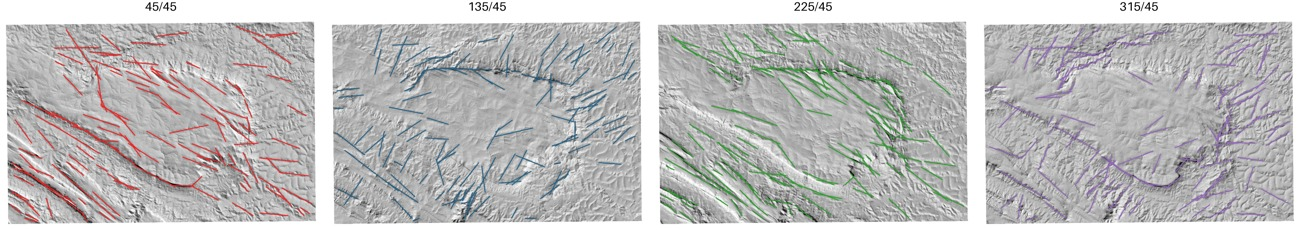

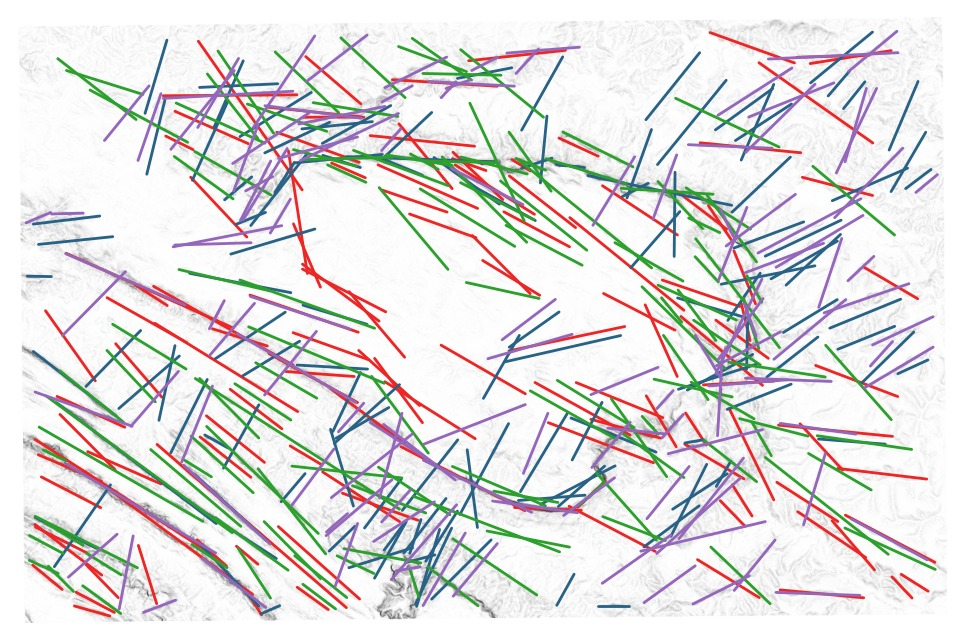

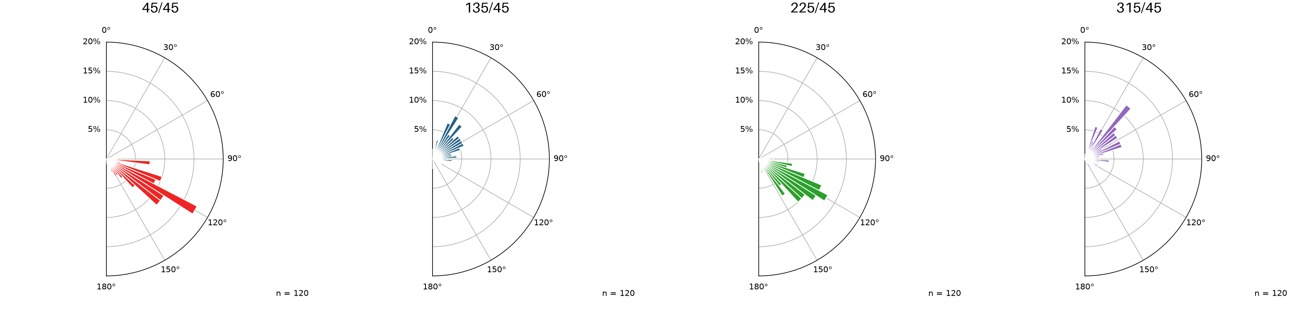

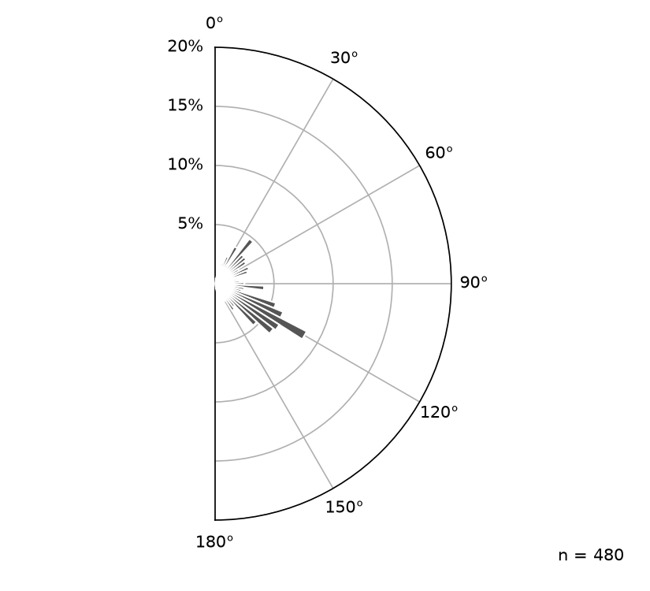

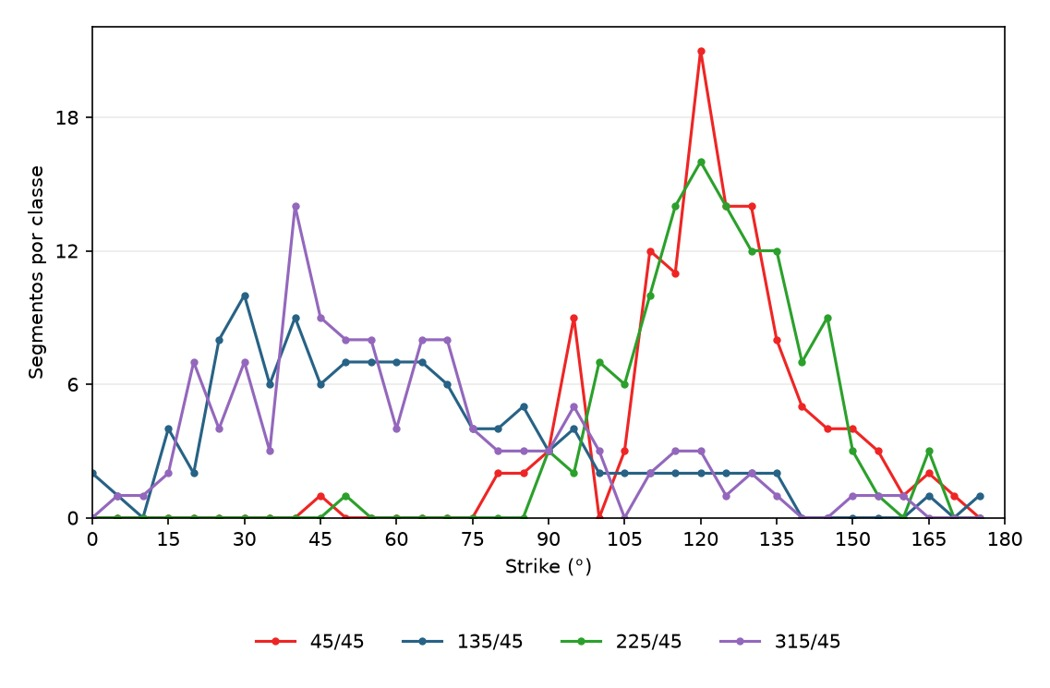

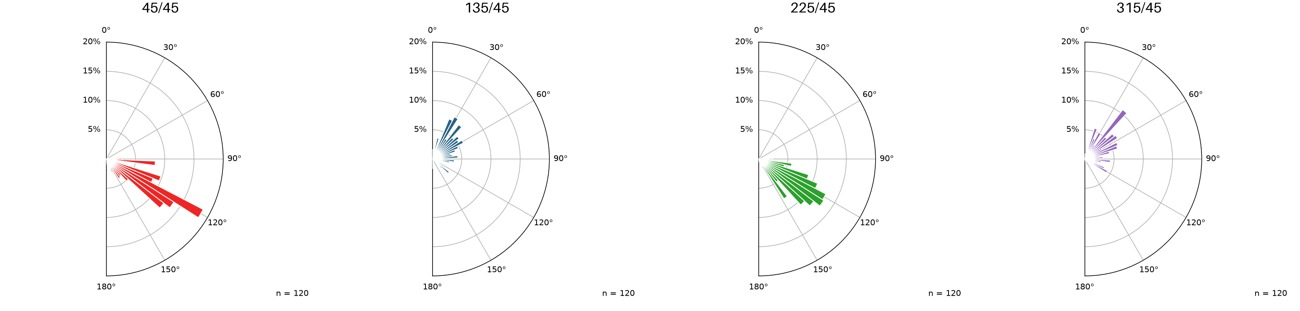

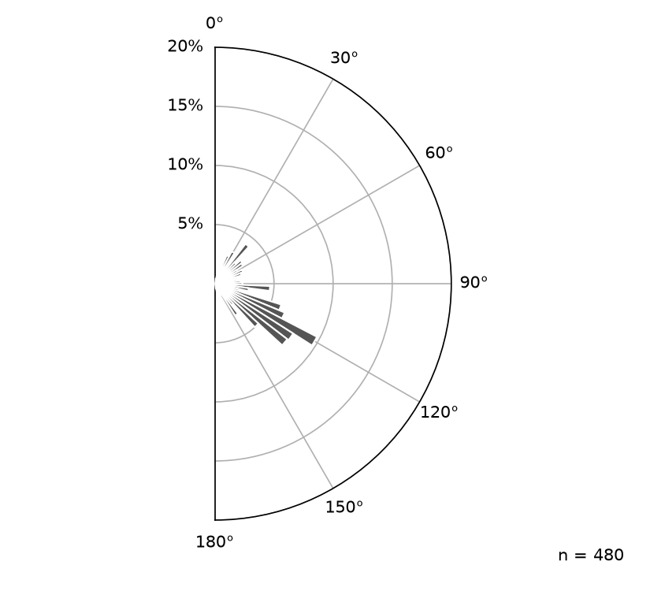

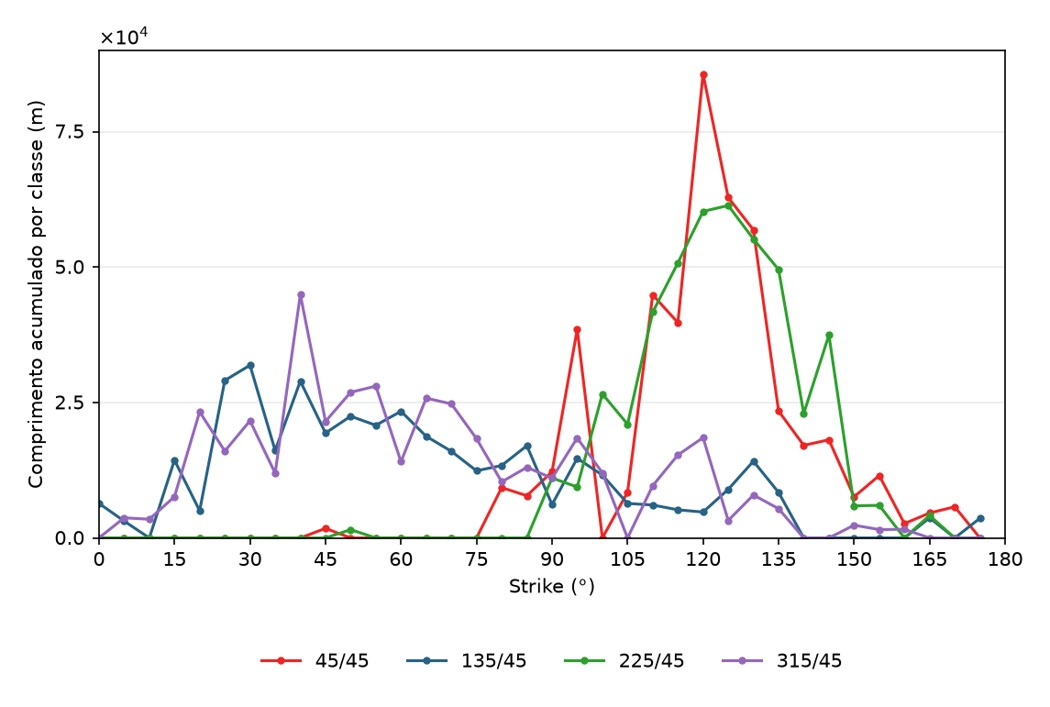

In [13]:
def montar_painel(caminhos, rotulos, destino):
    """Organize the images in input order with up to four columns."""
    tamanhos = []
    for caminho in caminhos:
        with Image.open(caminho) as imagem:
            tamanhos.append(imagem.size)

    largura = max(tamanho[0] for tamanho in tamanhos)
    altura = max(tamanho[1] for tamanho in tamanhos)
    n_colunas = min(4, len(caminhos))
    n_linhas = math.ceil(len(caminhos) / n_colunas)
    margem = 12
    faixa_rotulo = 48
    altura_quadro = altura + faixa_rotulo
    fonte = ImageFont.load_default(size=36)
    with Image.new("RGB", (
        largura * n_colunas + margem * (n_colunas - 1),
        altura_quadro * n_linhas + margem * (n_linhas - 1),
    ), "white") as painel:
        desenho = ImageDraw.Draw(painel)
        for i, (caminho, rotulo) in enumerate(zip(caminhos, rotulos, strict=True)):
            linha, coluna = divmod(i, n_colunas)
            esquerda = coluna * (largura + margem)
            topo = linha * (altura_quadro + margem)
            desenho.text((esquerda + largura // 2, topo + margem // 2), rotulo,
                         fill="black", font=fonte, anchor="mt")
            with Image.open(caminho) as imagem:
                x = esquerda + (largura - imagem.width) // 2
                y = topo + faixa_rotulo + (altura - imagem.height) // 2
                painel.paste(imagem.convert("RGB"), (x, y))
        painel.save(destino)


def mostrar_figura(caminho, largura):
    """Embed a preview while keeping the exported PNG at full resolution."""
    with Image.open(caminho) as imagem, BytesIO() as previa:
        imagem.thumbnail((largura, imagem.height))
        imagem.convert("RGB").save(previa, format="JPEG", quality=92)
        display(NotebookImage(data=previa.getvalue(), format="jpeg"))


def media_sombreados(caminhos):
    """Average illumination on the shared UTM grid and keep the nodata mask."""
    soma = None
    for caminho in caminhos:
        with rasterio.open(caminho) as raster:
            imagem = raster.read(1, masked=True).astype(np.float32)
        if soma is None:
            soma = imagem
        else:
            soma += imagem
    return soma / len(caminhos)


rotulos_paineis = [rotulos[luz] for luz in ILUMINACOES]
pasta_mapas = resultado / "sobreposicoes"
mapas = [pasta_mapas / f"{sombreado.stem}.png" for sombreado in sombreados]
painel_mapas = pasta_mapas / "comparacao_iluminacoes.png"
montar_painel(mapas, rotulos_paineis, painel_mapas)
mostrar_figura(painel_mapas, 1300)

rasters = [resultado / "hillshades" / sombreado.name for sombreado in sombreados]
series = [(segmentos, cores[luz]) for _, luz, segmentos, _ in deteccoes]
mapa = pasta_mapas / "mapa_combinado.png"
save_overlay(media_sombreados(rasters), mapa, series)
mostrar_figura(mapa, 1100)

centros, classes_combinadas = orientation_values(tabela["strike"], tabela["comp_m"])
for modo in ROSE_MODES:
    pasta_rosetas = resultado / "rosetas" / modo
    rosetas = [pasta_rosetas / f"{sombreado.stem}.png" for sombreado in sombreados]
    painel = pasta_rosetas / "comparacao_rosetas.png"
    montar_painel(rosetas, rotulos_paineis, painel)
    mostrar_figura(painel, 1300)

    roseta = pasta_rosetas / "roseta_combinada.png"
    save_rose(centros, classes_combinadas[modo], len(tabela), roseta, "#555555", escalas_radiais[modo])
    mostrar_figura(roseta, 650)

    grafico = pasta_rosetas / "comparacao_cartesiana.png"
    valores_por_luz = {luz: classes[modo] for luz, classes in classes_por_luz.items()}
    save_cartesian(grafico, centros, valores_por_luz, cores, rotulos, modo)
    mostrar_figura(grafico, 1050)